# RealWaste CNN Image Classification
## ITS69204 — Computer Vision and Natural Language Processing
### Individual Assignment — Taylor's University

**Dataset:** RealWaste (UCI ML Repository, ID: 908)  
**Task:** 9-class waste material classification  
**Models:** Custom CNN vs. EfficientNetB3 (Transfer Learning)  
**Framework:** TensorFlow / Keras  
**Environment:** Google Colab (GPU)

---
## Section 1 — Environment Setup & Library Imports

In [1]:
# ============================================================
# CELL 1: Install & Import All Required Libraries
# ============================================================

# Install ucimlrepo for direct dataset access
!pip install ucimlrepo --quiet

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks, regularizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.applications.efficientnet import preprocess_input as effnet_preprocess
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
)

# Scikit-learn — evaluation metrics
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score
)
from sklearn.utils.class_weight import compute_class_weight

# Set global random seeds for reproducibility
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Confirm GPU availability
print('TensorFlow version:', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print(f'GPU Available: {len(gpus) > 0} — Devices: {gpus}')

TensorFlow version: 2.20.0
GPU Available: True — Devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
## Section 2 — Dataset Download & Directory Setup

In [2]:
# ============================================================
# CELL 2: Download RealWaste Dataset from UCI Repository
# ============================================================
# The RealWaste dataset (UCI ID: 908) is downloaded directly
# via the ucimlrepo Python API. The dataset comprises 4,752
# colour images across 9 waste material categories.
# Source: Single, Iranmanesh, & Raad (2023)
# DOI: https://doi.org/10.24432/C5SS4G

# Option A: Download via ucimlrepo (metadata only — images need direct download)
# Option B: Download directly from GitHub mirror

# --- Download dataset images from GitHub ---
# Note: If using Kaggle, replace this block with the Kaggle API command
import zipfile
import urllib.request

DATASET_URL = 'https://github.com/sam-single/realwaste/archive/refs/heads/main.zip'
DATASET_ZIP = '/content/realwaste.zip'
DATASET_DIR = '/content/realwaste'

if not os.path.exists(DATASET_DIR):
    print('Downloading RealWaste dataset...')
    urllib.request.urlretrieve(DATASET_URL, DATASET_ZIP)
    print('Extracting...')
    with zipfile.ZipFile(DATASET_ZIP, 'r') as zf:
        zf.extractall('/content/')
    os.rename('/content/realwaste-main', DATASET_DIR)
    print('Dataset ready.')
else:
    print('Dataset already exists. Skipping download.')

# Define path to the RealWaste image directory
# Adjust subfolder name if needed after extraction
DATA_ROOT = DATASET_DIR + '/RealWaste'
print('\nDataset root:', DATA_ROOT)
print('Contents:', os.listdir(DATA_ROOT))

Extracting...
Dataset ready.

Dataset root: /content/realwaste/RealWaste
Contents: ['Food Organics', 'Textile Trash', 'Plastic', 'Cardboard', 'Paper', 'Vegetation', 'Metal', 'Miscellaneous Trash', 'Glass']


---
## Section 3 — Exploratory Data Analysis (EDA)

Total images in dataset: 4752

Class distribution:
  Plastic                    921 images  (19.4%)
  Metal                      790 images  (16.6%)
  Paper                      500 images  (10.5%)
  Miscellaneous Trash        495 images  (10.4%)
  Cardboard                  461 images  (9.7%)
  Vegetation                 436 images  (9.2%)
  Glass                      420 images  (8.8%)
  Food Organics              411 images  (8.6%)
  Textile Trash              318 images  (6.7%)


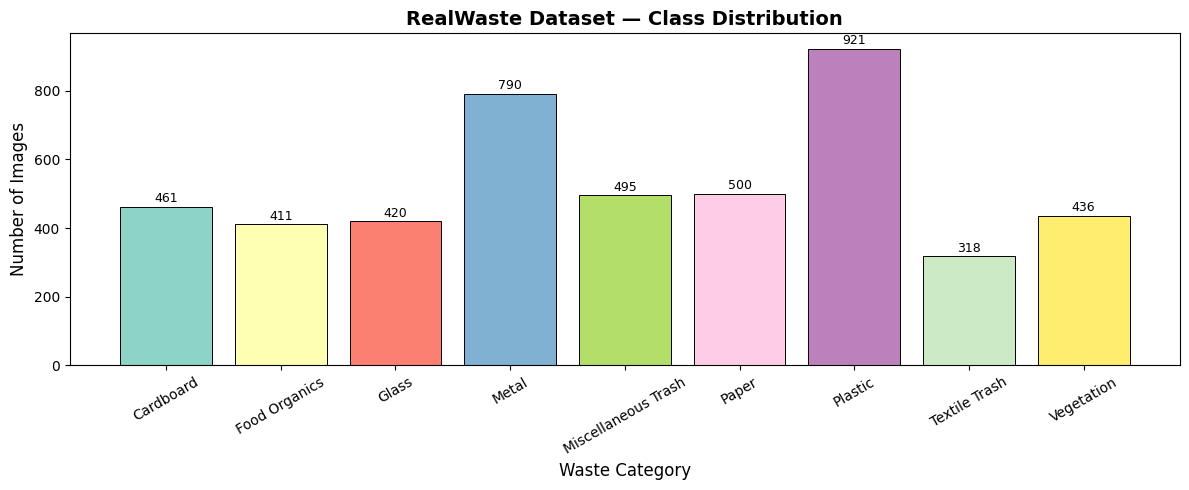

Figure saved: class_distribution.png


In [3]:
# ============================================================
# CELL 3: Class Distribution Analysis
# ============================================================
# Count images per class to identify class imbalance.
# RealWaste has known imbalance: Plastic (921) vs Textile (318).

# Define the 9 class names as per dataset documentation
CLASS_NAMES = [
    'Cardboard', 'Food Organics', 'Glass', 'Metal',
    'Miscellaneous Trash', 'Paper', 'Plastic',
    'Textile Trash', 'Vegetation'
]

# Count images per class
class_counts = {}
for class_name in CLASS_NAMES:
    class_path = os.path.join(DATA_ROOT, class_name)
    if os.path.exists(class_path):
        count = len([
            f for f in os.listdir(class_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ])
        class_counts[class_name] = count
    else:
        class_counts[class_name] = 0
        print(f'WARNING: Folder not found — {class_name}')

total_images = sum(class_counts.values())
print(f'Total images in dataset: {total_images}')
print('\nClass distribution:')
for cls, count in sorted(class_counts.items(), key=lambda x: -x[1]):
    pct = count / total_images * 100
    print(f'  {cls:<25} {count:>4} images  ({pct:.1f}%)')

# Visualise class distribution
fig, ax = plt.subplots(figsize=(12, 5))
colors = plt.cm.Set3(np.linspace(0, 1, len(CLASS_NAMES)))
bars = ax.bar(class_counts.keys(), class_counts.values(), color=colors, edgecolor='black', linewidth=0.7)
ax.set_title('RealWaste Dataset — Class Distribution', fontsize=14, fontweight='bold')
ax.set_xlabel('Waste Category', fontsize=12)
ax.set_ylabel('Number of Images', fontsize=12)
ax.tick_params(axis='x', rotation=30)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 5,
            str(int(bar.get_height())), ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig('/content/class_distribution.png', dpi=150)
plt.show()
print('Figure saved: class_distribution.png')

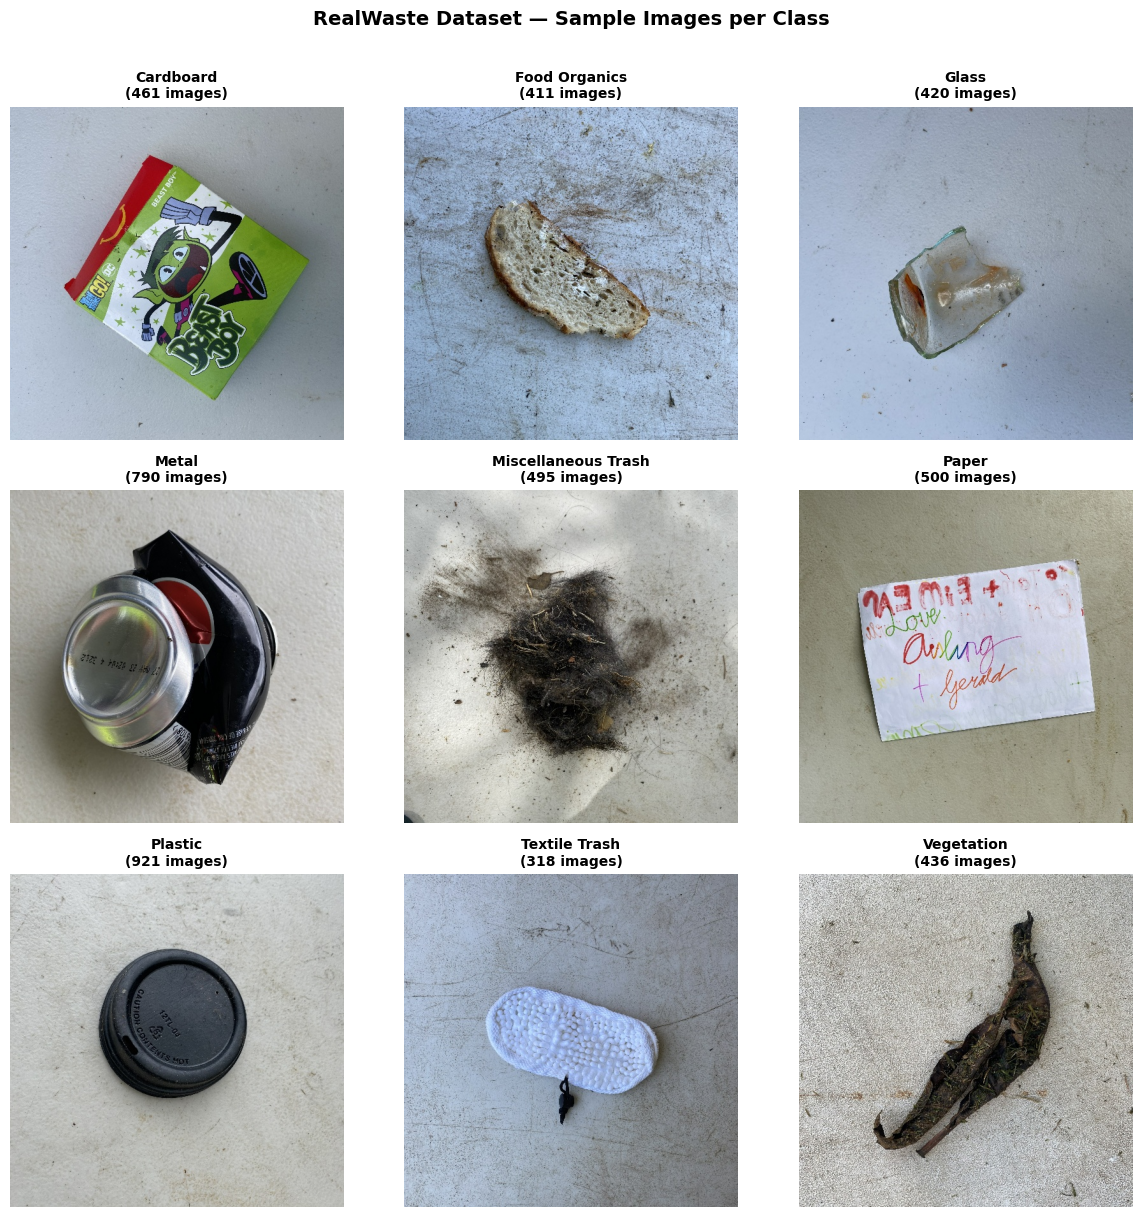

Figure saved: sample_images.png


In [4]:
# ============================================================
# CELL 4: Sample Images Display
# ============================================================
# Display representative sample images from each class to
# visually inspect image quality, variation, and challenges
# such as occlusion, contamination, and variable illumination.

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes = axes.flatten()

for idx, class_name in enumerate(CLASS_NAMES):
    class_path = os.path.join(DATA_ROOT, class_name)
    imgs = [f for f in os.listdir(class_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    sample_img = os.path.join(class_path, random.choice(imgs))
    img = mpimg.imread(sample_img)
    axes[idx].imshow(img)
    axes[idx].set_title(f'{class_name}\n({class_counts[class_name]} images)',
                        fontsize=10, fontweight='bold')
    axes[idx].axis('off')

plt.suptitle('RealWaste Dataset — Sample Images per Class',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('/content/sample_images.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved: sample_images.png')

---
## Section 4 — Data Preprocessing & Augmentation Pipeline

In [5]:
# ============================================================
# CELL 5: Global Configuration — Hyperparameters
# ============================================================
# All hyperparameters are defined here for easy modification
# and reproducibility. Documented per rubric requirement.

# --- Image Configuration ---
IMG_HEIGHT   = 224        # Resize height (pixels) — standard for ImageNet pretrained models
IMG_WIDTH    = 224        # Resize width (pixels)
IMG_CHANNELS = 3          # RGB colour channels
INPUT_SHAPE  = (IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS)

# --- Dataset Split ---
TRAIN_SPLIT  = 0.80       # 80% training data
TEST_SPLIT   = 0.20       # 20% testing data (held-out evaluation set)

# --- Training Hyperparameters ---
BATCH_SIZE   = 32         # Mini-batch size — balances memory efficiency and gradient stability
NUM_CLASSES  = 9          # Number of waste material categories

# --- Custom CNN Hyperparameters ---
CNN_EPOCHS        = 50    # Maximum training epochs
CNN_LEARNING_RATE = 5e-4  # Initial learning rate (Adam optimiser) — reduced from 1e-3 to stabilise from-scratch training
CNN_DROPOUT_RATE  = 0.5   # Dropout probability for regularisation
CNN_L2_REG        = 1e-4  # L2 weight decay regularisation coefficient

# --- EfficientNetB3 Transfer Learning Hyperparameters ---
TL_EPOCHS_FROZEN     = 20    # Epochs to train with frozen base model
TL_EPOCHS_FINETUNE   = 40    # V2: more room for fine-tuning (early stopping still guards)
TL_LR_FROZEN         = 1e-3  # Learning rate during frozen phase
TL_LR_FINETUNE       = 2e-5  # V2: raised from 1e-5 for faster fine-tune adaptation
TL_UNFREEZE_FROM     = 'block5a_expand_conv'  # V2: unfreeze deeper (was block6a) for more domain adaptation

# --- Paths ---
SAVE_DIR = '/content/models/'
os.makedirs(SAVE_DIR, exist_ok=True)

print('Configuration Summary:')
print(f'  Input Shape   : {INPUT_SHAPE}')
print(f'  Batch Size    : {BATCH_SIZE}')
print(f'  Num Classes   : {NUM_CLASSES}')
print(f'  Train Split   : {int(TRAIN_SPLIT*100)}%')
print(f'  Test Split    : {int(TEST_SPLIT*100)}%')
print(f'  CNN LR        : {CNN_LEARNING_RATE}')
print(f'  TL LR (frozen): {TL_LR_FROZEN}')
print(f'  TL LR (finetune): {TL_LR_FINETUNE}')

Configuration Summary:
  Input Shape   : (224, 224, 3)
  Batch Size    : 32
  Num Classes   : 9
  Train Split   : 80%
  Test Split    : 20%
  CNN LR        : 0.0005
  TL LR (frozen): 0.001
  TL LR (finetune): 2e-05


In [6]:
# ============================================================
# CELL 6: Compute Class Weights to Handle Class Imbalance
# ============================================================
# RealWaste has notable class imbalance (Plastic: 921 vs
# Textile Trash: 318). Class weights penalise the model more
# for misclassifying underrepresented classes during training,
# correcting the bias introduced by imbalanced data.

class_labels = list(range(NUM_CLASSES))  # 0 to 8
class_sample_counts = [class_counts[cn] for cn in CLASS_NAMES]

# Compute balanced class weights using sklearn
class_weight_values = compute_class_weight(
    class_weight='balanced',
    classes=np.array(class_labels),
    y=np.repeat(class_labels, class_sample_counts)
)
class_weight_dict = dict(enumerate(class_weight_values))

print('Computed Class Weights (higher = more penalised for errors):')
for idx, cls in enumerate(CLASS_NAMES):
    print(f'  Class {idx} — {cls:<25}: weight = {class_weight_dict[idx]:.4f}')

Computed Class Weights (higher = more penalised for errors):
  Class 0 — Cardboard                : weight = 1.1453
  Class 1 — Food Organics            : weight = 1.2847
  Class 2 — Glass                    : weight = 1.2571
  Class 3 — Metal                    : weight = 0.6684
  Class 4 — Miscellaneous Trash      : weight = 1.0667
  Class 5 — Paper                    : weight = 1.0560
  Class 6 — Plastic                  : weight = 0.5733
  Class 7 — Textile Trash            : weight = 1.6604
  Class 8 — Vegetation               : weight = 1.2110


In [7]:
# ============================================================
# CELL 7: Data Augmentation & Generator Setup
# ============================================================
# Data augmentation artificially expands the training set by
# applying random transformations, improving generalisation
# and reducing overfitting — critical for a dataset of 4,752 images.
#
# Augmentations selected to reflect realistic real-world variation:
#   - Horizontal flip: waste items have no canonical orientation
#   - Rotation: items may arrive at any angle on a conveyor
#   - Zoom: camera distance varies in field deployment
#   - Brightness/shear: replicates variable landfill lighting
#
# The test generator applies NO augmentation — only rescaling —
# to ensure unbiased evaluation on the held-out test set.

# Training data generator (with augmentation)
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,           # Normalise pixel values to [0, 1]
    validation_split=TEST_SPLIT,   # Reserve 20% as test set
    horizontal_flip=True,          # Random left-right flip
    vertical_flip=False,           # Vertical flip not realistic for waste
    rotation_range=15,             # Random rotation up to ±15 degrees (reduced from 25)
    zoom_range=0.10,               # Random zoom ±10% (reduced from 15%)
    width_shift_range=0.08,        # Horizontal shift ±8% (reduced from 10%)
    height_shift_range=0.08,       # Vertical shift ±8% (reduced from 10%)
    fill_mode='nearest'            # Fill empty pixels with nearest value
    # NOTE: brightness_range removed — it conflicts with rescale=1/255 in
    # ImageDataGenerator (known Keras issue) and injected batch-to-batch
    # scale noise that destabilised the from-scratch CNN's validation curve.
    # shear_range removed — over-aggressive for a shallow network trained from scratch.
)

# Test/validation data generator (NO augmentation)
test_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    validation_split=TEST_SPLIT
)

# Training generator — 80% of data
train_generator = train_datagen.flow_from_directory(
    DATA_ROOT,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',      # One-hot encoded labels for softmax output
    subset='training',
    shuffle=True,
    seed=SEED,
    classes=CLASS_NAMES
)

# Test generator — 20% of data (no shuffle for consistent evaluation)
test_generator = test_datagen.flow_from_directory(
    DATA_ROOT,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False,                 # Must be False for ordered predictions
    seed=SEED,
    classes=CLASS_NAMES
)

print(f'Training samples  : {train_generator.samples}')
print(f'Test samples      : {test_generator.samples}')
print(f'Class indices     : {train_generator.class_indices}')

Found 3803 images belonging to 9 classes.
Found 949 images belonging to 9 classes.
Training samples  : 3803
Test samples      : 949
Class indices     : {'Cardboard': 0, 'Food Organics': 1, 'Glass': 2, 'Metal': 3, 'Miscellaneous Trash': 4, 'Paper': 5, 'Plastic': 6, 'Textile Trash': 7, 'Vegetation': 8}


---
## Section 5 — Model A: Custom CNN Architecture

In [8]:
# ============================================================
# CELL 8: Custom CNN Architecture Definition
# ============================================================
# Architecture: 4-block convolutional network with progressive
# filter depth (32→64→128→256), Batch Normalisation, MaxPooling,
# Global Average Pooling, and a regularised classifier head.
#
# Design Rationale:
#   Block 1 (32 filters): Captures low-level features —
#     edges, colour gradients, and textures present in
#     waste images (e.g. cardboard corrugation, glass glint)
#
#   Block 2 (64 filters): Learns mid-level patterns —
#     surface textures, shapes, material boundaries
#
#   Block 3 (128 filters): Captures higher-order features —
#     object parts, material-specific surface characteristics
#
#   Block 4 (256 filters): Semantic feature representation —
#     full object recognition, class-discriminative features
#
#   Batch Normalisation: Stabilises training by normalising
#     layer inputs, allowing higher learning rates and
#     accelerating convergence
#
#   MaxPooling (2x2): Reduces spatial dimensions by 50%,
#     providing translation invariance and reducing parameters
#
#   Global Average Pooling: Replaces flatten+dense with spatial
#     averaging, drastically reducing parameters and overfitting
#
#   Dropout (0.5): Randomly zeroes 50% of neurons during
#     training, preventing co-adaptation and overfitting
#
#   L2 Regularisation: Penalises large weights in the dense
#     layer to encourage simpler generalisable representations

def build_custom_cnn(input_shape, num_classes, dropout_rate, l2_reg):
    """
    Constructs a 4-block custom CNN for 9-class waste classification.

    Parameters:
        input_shape  : tuple — (height, width, channels)
        num_classes  : int   — number of output classes (9)
        dropout_rate : float — dropout probability (0.5)
        l2_reg       : float — L2 regularisation coefficient (1e-4)

    Returns:
        model : tf.keras.Model — compiled CNN model
    """
    inputs = keras.Input(shape=input_shape, name='input_layer')

    # --- Convolutional Block 1: 32 filters ---
    x = layers.Conv2D(32, (3, 3), padding='same', activation='relu',
                      name='conv1_1')(inputs)
    x = layers.BatchNormalization(name='bn1_1')(x)
    x = layers.Conv2D(32, (3, 3), padding='same', activation='relu',
                      name='conv1_2')(x)
    x = layers.BatchNormalization(name='bn1_2')(x)
    x = layers.MaxPooling2D((2, 2), name='pool1')(x)  # 224→112

    # --- Convolutional Block 2: 64 filters ---
    x = layers.Conv2D(64, (3, 3), padding='same', activation='relu',
                      name='conv2_1')(x)
    x = layers.BatchNormalization(name='bn2_1')(x)
    x = layers.Conv2D(64, (3, 3), padding='same', activation='relu',
                      name='conv2_2')(x)
    x = layers.BatchNormalization(name='bn2_2')(x)
    x = layers.MaxPooling2D((2, 2), name='pool2')(x)  # 112→56

    # --- Convolutional Block 3: 128 filters ---
    x = layers.Conv2D(128, (3, 3), padding='same', activation='relu',
                      name='conv3_1')(x)
    x = layers.BatchNormalization(name='bn3_1')(x)
    x = layers.Conv2D(128, (3, 3), padding='same', activation='relu',
                      name='conv3_2')(x)
    x = layers.BatchNormalization(name='bn3_2')(x)
    x = layers.MaxPooling2D((2, 2), name='pool3')(x)  # 56→28

    # --- Convolutional Block 4: 256 filters ---
    x = layers.Conv2D(256, (3, 3), padding='same', activation='relu',
                      name='conv4_1')(x)
    x = layers.BatchNormalization(name='bn4_1')(x)
    x = layers.Conv2D(256, (3, 3), padding='same', activation='relu',
                      name='conv4_2')(x)
    x = layers.BatchNormalization(name='bn4_2')(x)
    x = layers.MaxPooling2D((2, 2), name='pool4')(x)  # 28→14

    # --- Global Average Pooling ---
    # Replaces Flatten to reduce parameters and overfitting risk
    x = layers.GlobalAveragePooling2D(name='global_avg_pool')(x)

    # --- Classifier Head ---
    x = layers.Dense(512, activation='relu',
                     kernel_regularizer=regularizers.l2(l2_reg),
                     name='dense_512')(x)
    x = layers.BatchNormalization(name='bn_dense')(x)
    x = layers.Dropout(dropout_rate, name='dropout')(x)

    # Output layer: softmax for multi-class probability distribution
    outputs = layers.Dense(num_classes, activation='softmax',
                           name='output_softmax')(x)

    model = keras.Model(inputs=inputs, outputs=outputs, name='Custom_CNN')
    return model


# Instantiate and compile the Custom CNN
custom_cnn = build_custom_cnn(
    input_shape=INPUT_SHAPE,
    num_classes=NUM_CLASSES,
    dropout_rate=CNN_DROPOUT_RATE,
    l2_reg=CNN_L2_REG
)

custom_cnn.compile(
    optimizer=Adam(learning_rate=CNN_LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Display architecture summary
custom_cnn.summary()

print(f'\nTotal parameters: {custom_cnn.count_params():,}')

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_1 (Conv2D)                │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1_1 (BatchNormalization)      │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_2 (Conv2D)                │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1_2 (BatchNormalization)      │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_1 (Conv2D)                │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2_1 (BatchNormalization)      │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_2 (Conv2D)                │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2_2 (BatchNormalization)      │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_1 (Conv2D)                │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3_1 (BatchNormalization)      │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_2 (Conv2D)                │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3_2 (BatchNormalization)      │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4_1 (Conv2D)                │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4_1 (BatchNormalization)      │ (None, 28, 28, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4_2 (Conv2D)                │ (None, 28, 28, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4_2 (BatchNormalization)      │ (None, 28, 28, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_512 (Dense)               │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_dense (BatchNormalization)   │ (None, 512)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,314,345 (5.01 MB)

 Trainable params: 1,311,401 (5.00 MB)

 Non-trainable params: 2,944 (11.50 KB)


Total parameters: 1,314,345


---
## Section 6 — Model A: Custom CNN Training

In [9]:
# ============================================================
# CELL 9: Custom CNN Training with Callbacks
# ============================================================
# Training callbacks defined:
#   EarlyStopping: Halts training when validation accuracy stops
#     improving for 10 consecutive epochs, restoring the best weights.
#     Prevents overfitting and unnecessary computation.
#
#   ReduceLROnPlateau: Reduces learning rate by 50% when validation
#     accuracy plateaus for 5 epochs. Helps escape local minima
#     and refine convergence toward the optimal solution.
#
#   ModelCheckpoint: Saves the best model weights to disk based
#     on validation accuracy, ensuring the optimal model is
#     preserved regardless of early stopping timing.

cnn_callbacks = [
    EarlyStopping(
        monitor='val_loss',          # val_loss is smoother than val_accuracy —
        patience=12,                 # picks a genuinely stable best epoch, not a lucky spike
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',          # react to loss plateaus for smoother LR decay
        factor=0.5,
        patience=4,                  # reduced from 5 — adapt learning rate sooner
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=SAVE_DIR + 'custom_cnn_best.keras',
        monitor='val_loss',          # checkpoint on the same stable metric
        save_best_only=True,
        verbose=1
    )
]

print('Starting Custom CNN training...')
print(f'  Epochs       : up to {CNN_EPOCHS} (early stopping active)')
print(f'  Batch Size   : {BATCH_SIZE}')
print(f'  Learning Rate: {CNN_LEARNING_RATE}')
print(f'  Class Weights: Applied (imbalance correction)')
print('=' * 50)

cnn_history = custom_cnn.fit(
    train_generator,
    epochs=CNN_EPOCHS,
    validation_data=test_generator,
    callbacks=cnn_callbacks,
    class_weight=class_weight_dict,  # Apply class weights
    verbose=1
)

print('\nCustom CNN training complete.')

Starting Custom CNN training...
  Epochs       : up to 50 (early stopping active)
  Batch Size   : 32
  Learning Rate: 0.0005
  Class Weights: Applied (imbalance correction)
Epoch 1/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 660ms/step - accuracy: 0.3822 - loss: 2.1281
Epoch 1: val_loss improved from None to 2.54634, saving model to /content/models/custom_cnn_best.keras

Epoch 1: finished saving model to /content/models/custom_cnn_best.keras
119/119 ━━━━━━━━━━━━━━━━━━━━ 124s 762ms/step - accuracy: 0.4249 - loss: 1.9207 - val_accuracy: 0.0664 - val_loss: 2.5463 - learning_rate: 5.0000e-04
Epoch 2/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 494ms/step - accuracy: 0.4828 - loss: 1.6218
Epoch 2: val_loss did not improve from 2.54634
119/119 ━━━━━━━━━━━━━━━━━━━━ 63s 527ms/step - accuracy: 0.4878 - loss: 1.5840 - val_accuracy: 0.1697 - val_loss: 3.8002 - learning_rate: 5.0000e-04
Epoch 3/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 494ms/step - accuracy: 0.5111 - loss: 1.4895
Epoch 3: val_loss did not improve from 2.5

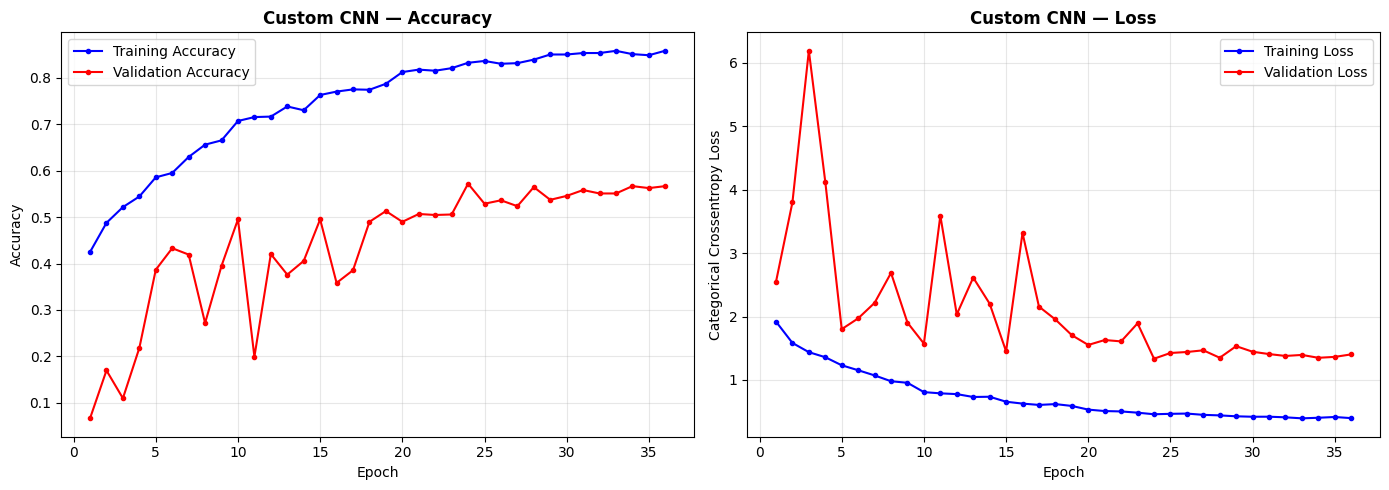

Figure saved: /content/cnn_training_curves.png


In [10]:
# ============================================================
# CELL 10: Plot Custom CNN Training Curves
# ============================================================
# Training and validation accuracy/loss curves are plotted
# to visually assess convergence behaviour, overfitting,
# and the effect of callbacks on training dynamics.

def plot_training_history(history, model_name, save_path):
    """
    Plots training & validation accuracy and loss curves.

    Parameters:
        history    : keras History object from model.fit()
        model_name : str — label for plot title
        save_path  : str — path to save the figure
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    epochs_run = range(1, len(history.history['accuracy']) + 1)

    # Accuracy subplot
    ax1.plot(epochs_run, history.history['accuracy'],
             'b-o', markersize=3, label='Training Accuracy')
    ax1.plot(epochs_run, history.history['val_accuracy'],
             'r-o', markersize=3, label='Validation Accuracy')
    ax1.set_title(f'{model_name} — Accuracy', fontweight='bold')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Accuracy')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # Loss subplot
    ax2.plot(epochs_run, history.history['loss'],
             'b-o', markersize=3, label='Training Loss')
    ax2.plot(epochs_run, history.history['val_loss'],
             'r-o', markersize=3, label='Validation Loss')
    ax2.set_title(f'{model_name} — Loss', fontweight='bold')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Categorical Crossentropy Loss')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()
    print(f'Figure saved: {save_path}')


plot_training_history(
    cnn_history,
    'Custom CNN',
    '/content/cnn_training_curves.png'
)

---
## Section 7 — Model B: EfficientNetB3 Transfer Learning

In [11]:
# ============================================================
# CELL 11: EfficientNetB3 Transfer Learning Setup
# ============================================================
# EfficientNetB3 is selected as the transfer learning baseline
# for the following reasons:
#   1. Trained on ImageNet (1.28M images, 1000 classes) —
#      rich hierarchical visual features directly applicable
#      to waste material recognition (textures, shapes, surfaces)
#   2. Compound scaling: simultaneously scales depth, width,
#      and resolution, achieving superior accuracy-efficiency
#      trade-off compared to VGG16, ResNet50, and MobileNetV2
#   3. Outperforms InceptionV3 (used in the original RealWaste
#      paper) at equivalent parameter budgets, enabling a
#      meaningful contribution beyond the existing literature
#   4. Input size 300×300 compatible; we use 224×224 with
#      include_top=False to accommodate our input pipeline
#
# Two-phase training strategy:
#   Phase 1 (Frozen Base): Train only the classifier head
#     with the EfficientNetB3 base frozen. Allows the
#     classifier to learn waste-specific representations
#     without disrupting pre-trained ImageNet weights.
#   Phase 2 (Fine-tuning): Unfreeze top layers of the base
#     and continue training at a very low learning rate (1e-5),
#     allowing domain-specific refinement of deep features
#     while preserving low-level ImageNet representations.

# --- EfficientNetB3 data generators (with EfficientNet preprocessing) ---
# EfficientNet expects pixel values in [0, 255] — preprocessing
# is handled internally by the effnet_preprocess function

tl_train_datagen = ImageDataGenerator(
    preprocessing_function=effnet_preprocess,
    validation_split=TEST_SPLIT,
    horizontal_flip=True,
    rotation_range=25,
    zoom_range=0.15,
    shear_range=0.10,
    brightness_range=[0.75, 1.25],
    width_shift_range=0.10,
    height_shift_range=0.10,
    fill_mode='nearest'
)

tl_test_datagen = ImageDataGenerator(
    preprocessing_function=effnet_preprocess,
    validation_split=TEST_SPLIT
)

tl_train_generator = tl_train_datagen.flow_from_directory(
    DATA_ROOT,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=SEED,
    classes=CLASS_NAMES
)

tl_test_generator = tl_test_datagen.flow_from_directory(
    DATA_ROOT,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False,
    seed=SEED,
    classes=CLASS_NAMES
)

print(f'TL Training samples: {tl_train_generator.samples}')
print(f'TL Test samples    : {tl_test_generator.samples}')

Found 3803 images belonging to 9 classes.
Found 949 images belonging to 9 classes.
TL Training samples: 3803
TL Test samples    : 949


In [12]:
# ============================================================
# CELL 12: Build EfficientNetB3 Model
# ============================================================

def build_efficientnetb3(input_shape, num_classes):
    """
    Builds EfficientNetB3 transfer learning model.

    Architecture:
        Base: EfficientNetB3 (ImageNet pretrained, frozen)
        Head: GlobalAveragePooling2D → Dense(256) → BN → Dropout(0.4)
              → Dense(num_classes, softmax)

    Parameters:
        input_shape : tuple
        num_classes : int

    Returns:
        model : tf.keras.Model
    """
    # Load EfficientNetB3 pretrained on ImageNet, exclude top classifier
    base_model = EfficientNetB3(
        input_shape=input_shape,
        include_top=False,        # Exclude ImageNet 1000-class head
        weights='imagenet'        # Use pretrained ImageNet weights
    )
    # Freeze all base model layers (Phase 1)
    base_model.trainable = False

    # Build custom classification head on top of frozen base
    inputs = keras.Input(shape=input_shape, name='input_layer')
    x = base_model(inputs, training=False)  # training=False: BN layers use inference mode
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.Dense(256, activation='relu', name='dense_256')(x)
    x = layers.BatchNormalization(name='bn_head')(x)
    x = layers.Dropout(0.4, name='dropout_head')(x)
    outputs = layers.Dense(num_classes, activation='softmax', name='output')(x)

    model = keras.Model(inputs=inputs, outputs=outputs, name='EfficientNetB3_TL')
    return model, base_model


effnet_model, effnet_base = build_efficientnetb3(INPUT_SHAPE, NUM_CLASSES)

effnet_model.compile(
    optimizer=Adam(learning_rate=TL_LR_FROZEN),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

effnet_model.summary()
trainable = sum(tf.size(v).numpy() for v in effnet_model.trainable_variables)
total = sum(tf.size(v).numpy() for v in effnet_model.variables)
print(f'\nTrainable parameters (Phase 1): {trainable:,} / {total:,} total')

43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "EfficientNetB3_TL"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb3 (Functional)     │ (None, 7, 7, 1536)     │    10,783,535 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │       393,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_head (BatchNormalization)    │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_head (Dropout)          │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 9)              │         2,313 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,180,344 (42.65 MB)

 Trainable params: 396,297 (1.51 MB)

 Non-trainable params: 10,784,047 (41.14 MB)


Trainable parameters (Phase 1): 396,297 / 11,180,384 total


In [13]:
# ============================================================
# CELL 13: Phase 1 Training — Frozen Base
# ============================================================

tl_callbacks_phase1 = [
    EarlyStopping(monitor='val_accuracy', patience=7,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_accuracy', factor=0.5,
                      patience=3, min_lr=1e-7, verbose=1),
    ModelCheckpoint(SAVE_DIR + 'effnet_phase1_best.keras',
                    monitor='val_accuracy', save_best_only=True, verbose=1)
]

print('Phase 1: Training classifier head with frozen EfficientNetB3 base...')
print(f'  Epochs       : up to {TL_EPOCHS_FROZEN}')
print(f'  Learning Rate: {TL_LR_FROZEN}')
print('=' * 50)

tl_history_phase1 = effnet_model.fit(
    tl_train_generator,
    epochs=TL_EPOCHS_FROZEN,
    validation_data=tl_test_generator,
    callbacks=tl_callbacks_phase1,
    class_weight=class_weight_dict,
    verbose=1
)

print('\nPhase 1 training complete.')
print(f"Best val accuracy: {max(tl_history_phase1.history['val_accuracy']):.4f}")

Phase 1: Training classifier head with frozen EfficientNetB3 base...
  Epochs       : up to 20
  Learning Rate: 0.001
Epoch 1/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 749ms/step - accuracy: 0.5329 - loss: 1.4860
Epoch 1: val_accuracy improved from None to 0.63014, saving model to /content/models/effnet_phase1_best.keras

Epoch 1: finished saving model to /content/models/effnet_phase1_best.keras
119/119 ━━━━━━━━━━━━━━━━━━━━ 170s 1s/step - accuracy: 0.6419 - loss: 1.1098 - val_accuracy: 0.6301 - val_loss: 1.0497 - learning_rate: 0.0010
Epoch 2/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 525ms/step - accuracy: 0.7627 - loss: 0.6845
Epoch 2: val_accuracy improved from 0.63014 to 0.66386, saving model to /content/models/effnet_phase1_best.keras

Epoch 2: finished saving model to /content/models/effnet_phase1_best.keras
119/119 ━━━━━━━━━━━━━━━━━━━━ 67s 567ms/step - accuracy: 0.7720 - loss: 0.6436 - val_accuracy: 0.6639 - val_loss: 0.9839 - learning_rate: 0.0010
Epoch 3/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 52

In [14]:
# ============================================================
# CELL 14: Phase 2 Training — Fine-Tuning
# ============================================================
# Unfreeze the top blocks of EfficientNetB3 and retrain at
# a very low learning rate (1e-5) to prevent catastrophic
# forgetting of ImageNet representations while adapting
# deep features to the waste classification domain.

# Unfreeze top layers of EfficientNetB3 from block6a onwards
effnet_base.trainable = True
fine_tune_at = None
for layer in effnet_base.layers:
    if layer.name == TL_UNFREEZE_FROM:
        fine_tune_at = True
    if fine_tune_at is None:
        layer.trainable = False  # Keep frozen
    else:
        layer.trainable = True   # Unfreeze

# Recompile with a low learning rate for fine-tuning
effnet_model.compile(
    optimizer=Adam(learning_rate=TL_LR_FINETUNE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

trainable_ft = sum(tf.size(v).numpy() for v in effnet_model.trainable_variables)
print(f'Trainable parameters (Phase 2): {trainable_ft:,}')

tl_callbacks_phase2 = [
    EarlyStopping(monitor='val_loss', patience=12,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=5, min_lr=1e-8, verbose=1),
    ModelCheckpoint(SAVE_DIR + 'effnet_phase2_best.keras',
                    monitor='val_accuracy', save_best_only=True, verbose=1)
]

print('Phase 2: Fine-tuning unfrozen EfficientNetB3 layers...')
print(f'  Epochs       : up to {TL_EPOCHS_FINETUNE}')
print(f'  Learning Rate: {TL_LR_FINETUNE}')
print('=' * 50)

tl_history_phase2 = effnet_model.fit(
    tl_train_generator,
    epochs=TL_EPOCHS_FINETUNE,
    validation_data=tl_test_generator,
    callbacks=tl_callbacks_phase2,
    class_weight=class_weight_dict,
    verbose=1
)

print('\nPhase 2 fine-tuning complete.')
print(f"Best val accuracy: {max(tl_history_phase2.history['val_accuracy']):.4f}")

# ============================================================
# V2 SAFEGUARD: keep the BEST of Phase 1 vs Phase 2
# ------------------------------------------------------------
# Fine-tuning can end below Phase 1's peak. We evaluate both saved
# checkpoints on the test set and load whichever is stronger into
# effnet_model, so the final evaluated model is never worse than
# the frozen-base result.
# ============================================================
p1_acc = max(tl_history_phase1.history['val_accuracy'])
p2_acc = max(tl_history_phase2.history['val_accuracy'])
print(f'\nPhase 1 best val_accuracy: {p1_acc:.4f}')
print(f'Phase 2 best val_accuracy: {p2_acc:.4f}')

if p1_acc > p2_acc:
    print('Phase 1 was stronger — reloading Phase 1 checkpoint into effnet_model.')
    effnet_model = keras.models.load_model(SAVE_DIR + 'effnet_phase1_best.keras')
else:
    print('Phase 2 was stronger — reloading Phase 2 checkpoint into effnet_model.')
    effnet_model = keras.models.load_model(SAVE_DIR + 'effnet_phase2_best.keras')
print('Final EfficientNetB3 model loaded for evaluation.')


Trainable parameters (Phase 2): 10,290,135
Phase 2: Fine-tuning unfrozen EfficientNetB3 layers...
  Epochs       : up to 40
  Learning Rate: 2e-05
Epoch 1/40
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 884ms/step - accuracy: 0.6851 - loss: 1.0261
Epoch 1: val_accuracy improved from None to 0.73130, saving model to /content/models/effnet_phase2_best.keras

Epoch 1: finished saving model to /content/models/effnet_phase2_best.keras
119/119 ━━━━━━━━━━━━━━━━━━━━ 208s 1s/step - accuracy: 0.7118 - loss: 0.9185 - val_accuracy: 0.7313 - val_loss: 0.9945 - learning_rate: 2.0000e-05
Epoch 2/40
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 548ms/step - accuracy: 0.7731 - loss: 0.6816
Epoch 2: val_accuracy did not improve from 0.73130
119/119 ━━━━━━━━━━━━━━━━━━━━ 69s 581ms/step - accuracy: 0.7854 - loss: 0.6384 - val_accuracy: 0.6934 - val_loss: 1.1204 - learning_rate: 2.0000e-05
Epoch 3/40
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 553ms/step - accuracy: 0.8225 - loss: 0.5077
Epoch 3: val_accuracy did not improve from 0.73130
119/119

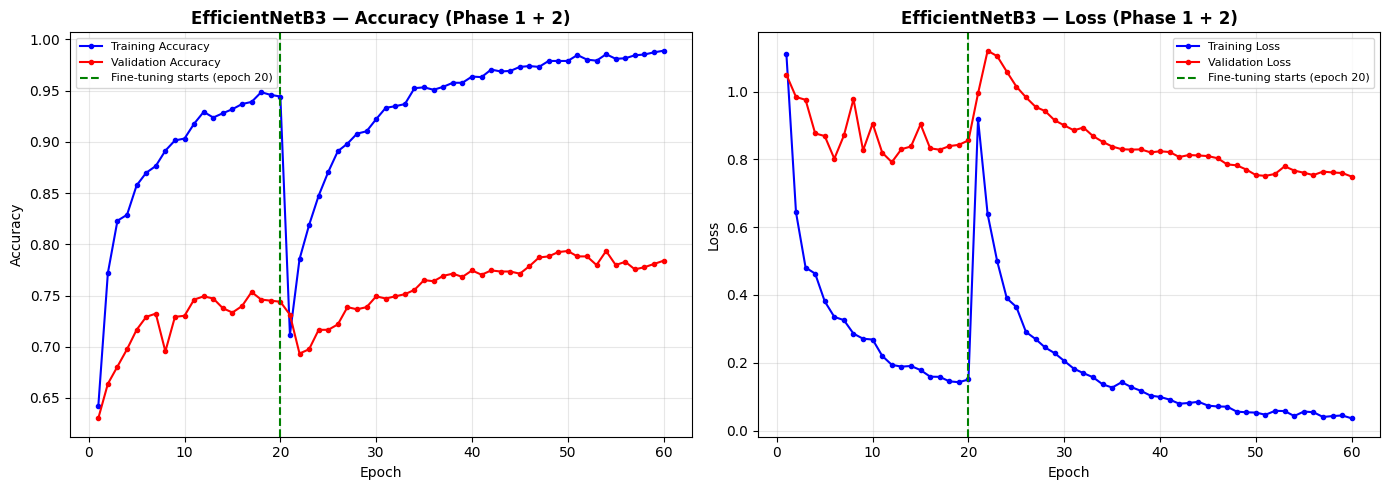

Figure saved: effnet_training_curves.png


In [15]:
# ============================================================
# CELL 15: Plot EfficientNetB3 Training Curves (Both Phases)
# ============================================================

# Combine Phase 1 and Phase 2 histories
combined_acc = (tl_history_phase1.history['accuracy'] +
                tl_history_phase2.history['accuracy'])
combined_val_acc = (tl_history_phase1.history['val_accuracy'] +
                    tl_history_phase2.history['val_accuracy'])
combined_loss = (tl_history_phase1.history['loss'] +
                 tl_history_phase2.history['loss'])
combined_val_loss = (tl_history_phase1.history['val_loss'] +
                     tl_history_phase2.history['val_loss'])

phase1_end = len(tl_history_phase1.history['accuracy'])
epochs_all  = range(1, len(combined_acc) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epochs_all, combined_acc, 'b-o', markersize=3, label='Training Accuracy')
ax1.plot(epochs_all, combined_val_acc, 'r-o', markersize=3, label='Validation Accuracy')
ax1.axvline(x=phase1_end, color='green', linestyle='--', linewidth=1.5,
            label=f'Fine-tuning starts (epoch {phase1_end})')
ax1.set_title('EfficientNetB3 — Accuracy (Phase 1 + 2)', fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

ax2.plot(epochs_all, combined_loss, 'b-o', markersize=3, label='Training Loss')
ax2.plot(epochs_all, combined_val_loss, 'r-o', markersize=3, label='Validation Loss')
ax2.axvline(x=phase1_end, color='green', linestyle='--', linewidth=1.5,
            label=f'Fine-tuning starts (epoch {phase1_end})')
ax2.set_title('EfficientNetB3 — Loss (Phase 1 + 2)', fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/content/effnet_training_curves.png', dpi=150)
plt.show()
print('Figure saved: effnet_training_curves.png')

---
## Section 8 — Evaluation: Metrics, Confusion Matrices & Comparison

In [16]:
# ============================================================
# CELL 16: Evaluation Helper Function
# ============================================================
# Computes and displays full evaluation metrics:
#   - Overall accuracy, macro precision, recall, F1-score
#   - Per-class precision, recall, F1 via classification_report
#   - Normalised confusion matrix heatmap

def evaluate_model(model, generator, class_names, model_name, save_prefix):
    """
    Evaluates a trained Keras model on a data generator.

    Parameters:
        model       : tf.keras.Model — trained model
        generator   : ImageDataGenerator — test generator (shuffle=False)
        class_names : list — ordered list of class names
        model_name  : str  — label for display
        save_prefix : str  — file prefix for saved figures

    Returns:
        results : dict — accuracy, precision, recall, f1
    """
    generator.reset()  # Ensure generator starts from the beginning

    # Predict all test samples
    y_pred_probs = model.predict(generator, verbose=1)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = generator.classes

    # Overall metrics
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro', zero_division=0)
    rec  = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1   = f1_score(y_true, y_pred, average='macro', zero_division=0)

    print(f'\n{"="*55}')
    print(f'  {model_name} — Evaluation Results')
    print(f'{"="*55}')
    print(f'  Accuracy  (Overall)  : {acc:.4f} ({acc*100:.2f}%)')
    print(f'  Precision (Macro)    : {prec:.4f}')
    print(f'  Recall    (Macro)    : {rec:.4f}')
    print(f'  F1-Score  (Macro)    : {f1:.4f}')
    print(f'{"="*55}')

    # Per-class report
    print(f'\nPer-Class Report:')
    print(classification_report(y_true, y_pred,
                                 target_names=class_names, digits=4))

    # Normalised confusion matrix
    cm = confusion_matrix(y_true, y_pred, normalize='true')
    fig, ax = plt.subplots(figsize=(11, 9))
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                linewidths=0.5, ax=ax)
    ax.set_title(f'{model_name} — Normalised Confusion Matrix',
                 fontsize=13, fontweight='bold')
    ax.set_ylabel('True Label', fontsize=11)
    ax.set_xlabel('Predicted Label', fontsize=11)
    ax.tick_params(axis='x', rotation=35)
    ax.tick_params(axis='y', rotation=0)
    plt.tight_layout()
    plt.savefig(f'/content/{save_prefix}_confusion_matrix.png', dpi=150)
    plt.show()
    print(f'Confusion matrix saved: {save_prefix}_confusion_matrix.png')

    return {'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1}

30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 140ms/step

  Custom CNN — Evaluation Results
  Accuracy  (Overall)  : 0.5722 (57.22%)
  Precision (Macro)    : 0.6151
  Recall    (Macro)    : 0.5946
  F1-Score  (Macro)    : 0.5930

Per-Class Report:
                     precision    recall  f1-score   support

          Cardboard     0.3802    0.5000    0.4319        92
      Food Organics     0.9608    0.5976    0.7368        82
              Glass     0.7113    0.8214    0.7624        84
              Metal     0.5923    0.4873    0.5347       158
Miscellaneous Trash     0.4779    0.5455    0.5094        99
              Paper     0.5965    0.3400    0.4331       100
            Plastic     0.4545    0.5163    0.4835       184
      Textile Trash     0.5128    0.6349    0.5674        63
         Vegetation     0.8495    0.9080    0.8778        87

           accuracy                         0.5722       949
          macro avg     0.6151    0.5946    0.5930       949
       weighted avg     0.5942    

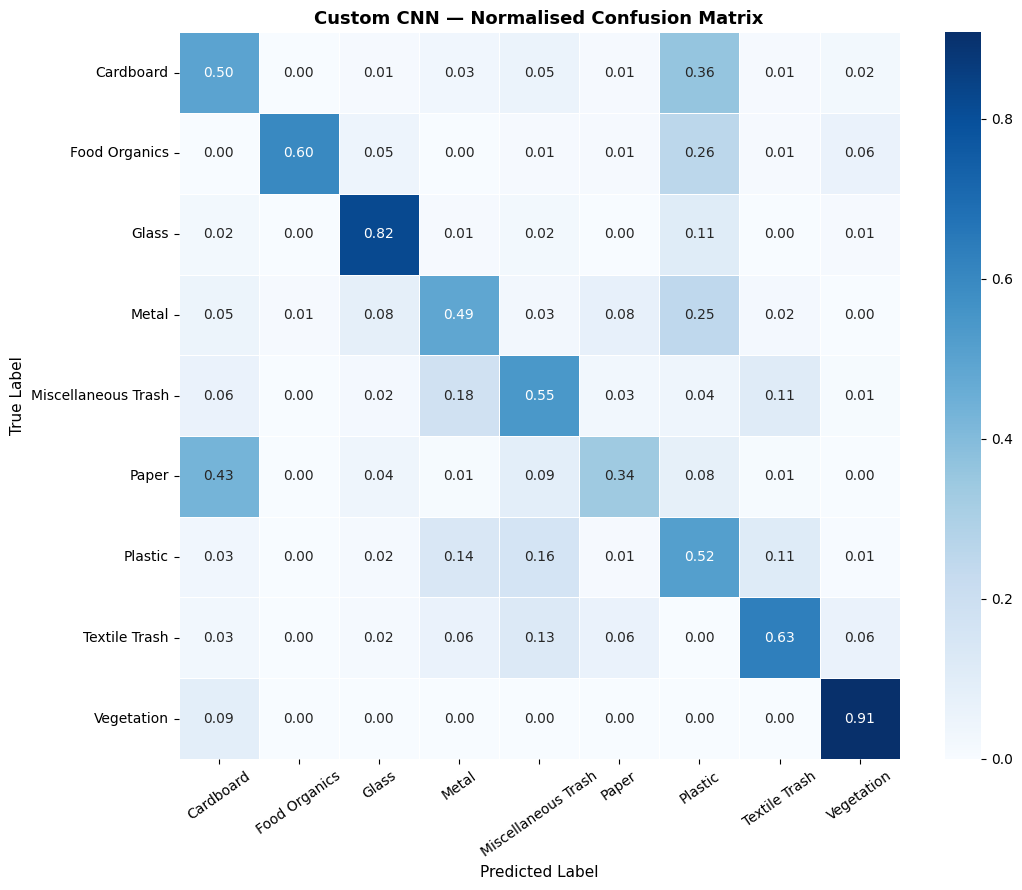

Confusion matrix saved: custom_cnn_confusion_matrix.png


In [17]:
# ============================================================
# CELL 17: Evaluate Custom CNN
# ============================================================

cnn_results = evaluate_model(
    model=custom_cnn,
    generator=test_generator,
    class_names=CLASS_NAMES,
    model_name='Custom CNN',
    save_prefix='custom_cnn'
)

30/30 ━━━━━━━━━━━━━━━━━━━━ 24s 471ms/step

  EfficientNetB3 (Transfer Learning) — Evaluation Results
  Accuracy  (Overall)  : 0.7935 (79.35%)
  Precision (Macro)    : 0.7960
  Recall    (Macro)    : 0.8063
  F1-Score  (Macro)    : 0.7983

Per-Class Report:
                     precision    recall  f1-score   support

          Cardboard     0.7011    0.6630    0.6816        92
      Food Organics     0.9315    0.8293    0.8774        82
              Glass     0.8750    0.9167    0.8953        84
              Metal     0.7684    0.8608    0.8119       158
Miscellaneous Trash     0.6804    0.6667    0.6735        99
              Paper     0.7670    0.7900    0.7783       100
            Plastic     0.8289    0.6848    0.7500       184
      Textile Trash     0.6667    0.8571    0.7500        63
         Vegetation     0.9451    0.9885    0.9663        87

           accuracy                         0.7935       949
          macro avg     0.7960    0.8063    0.7983       949
       we

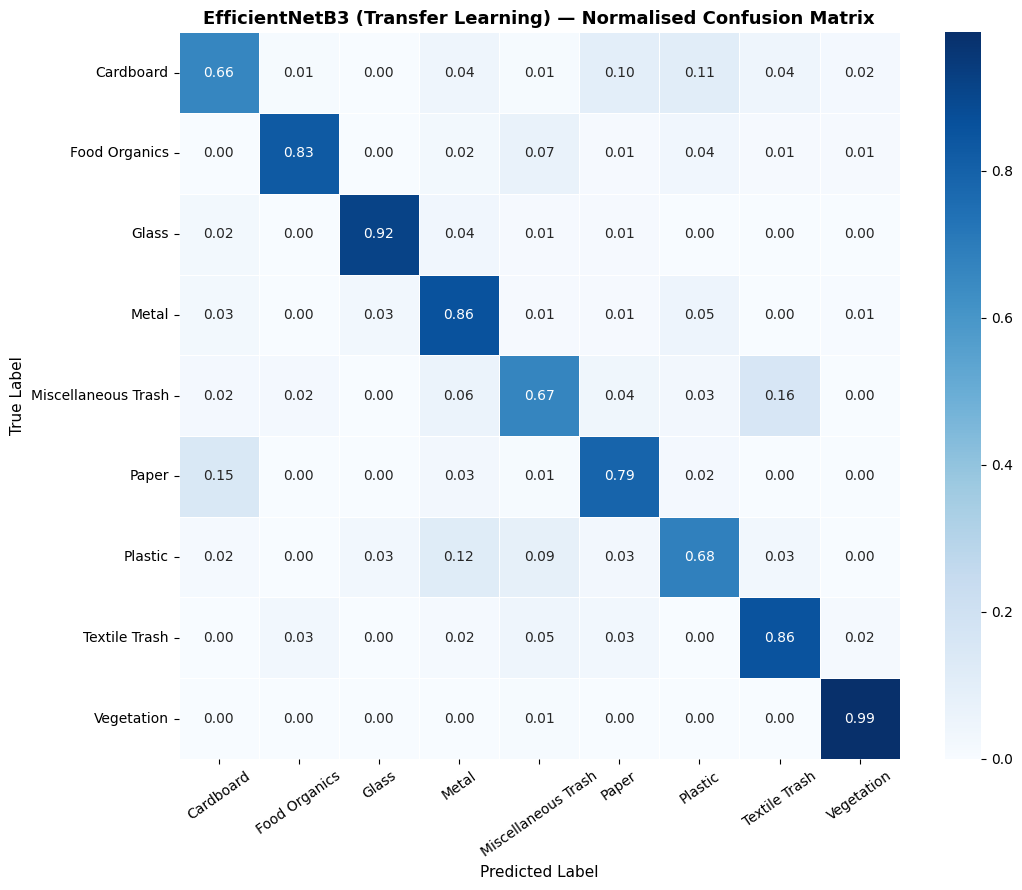

Confusion matrix saved: efficientnetb3_confusion_matrix.png


In [18]:
# ============================================================
# CELL 18: Evaluate EfficientNetB3
# ============================================================

effnet_results = evaluate_model(
    model=effnet_model,
    generator=tl_test_generator,
    class_names=CLASS_NAMES,
    model_name='EfficientNetB3 (Transfer Learning)',
    save_prefix='efficientnetb3'
)


Model Comparison Summary:
              Model  Accuracy  Precision  Recall  F1-Score
         Custom CNN    0.5722     0.6151  0.5946    0.5930
EfficientNetB3 (TL)    0.7935     0.7960  0.8063    0.7983


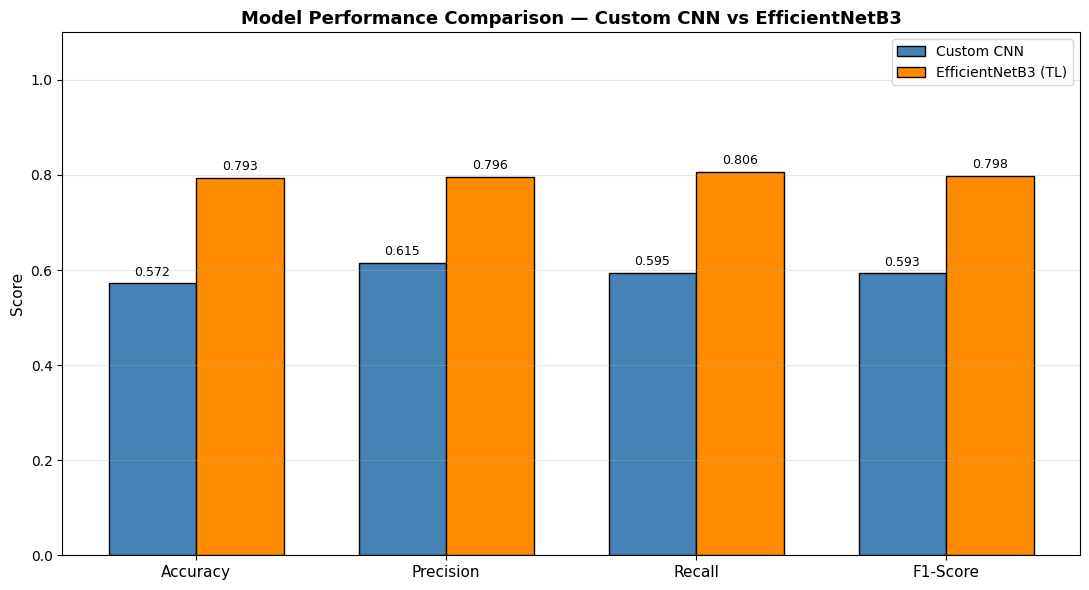

Figure saved: model_comparison.png


In [19]:
# ============================================================
# CELL 19: Model Comparison Summary Table & Bar Chart
# ============================================================

comparison_data = {
    'Model': ['Custom CNN', 'EfficientNetB3 (TL)'],
    'Accuracy':  [cnn_results['accuracy'],  effnet_results['accuracy']],
    'Precision': [cnn_results['precision'], effnet_results['precision']],
    'Recall':    [cnn_results['recall'],    effnet_results['recall']],
    'F1-Score':  [cnn_results['f1'],        effnet_results['f1']]
}

df_comparison = pd.DataFrame(comparison_data)
print('\nModel Comparison Summary:')
print(df_comparison.to_string(index=False, float_format='{:.4f}'.format))

# Bar chart comparison
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))
bars1 = ax.bar(x - width/2,
               [cnn_results['accuracy'], cnn_results['precision'],
                cnn_results['recall'],   cnn_results['f1']],
               width, label='Custom CNN', color='steelblue', edgecolor='black')
bars2 = ax.bar(x + width/2,
               [effnet_results['accuracy'], effnet_results['precision'],
                effnet_results['recall'],   effnet_results['f1']],
               width, label='EfficientNetB3 (TL)', color='darkorange', edgecolor='black')

ax.set_title('Model Performance Comparison — Custom CNN vs EfficientNetB3',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Score', fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylim(0, 1.1)
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)

# Annotate bars with values
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('/content/model_comparison.png', dpi=150)
plt.show()
print('Figure saved: model_comparison.png')

In [20]:
# ============================================================
# CELL 20: Save Final Models
# ============================================================

# Save complete models in Keras format
custom_cnn.save(SAVE_DIR + 'custom_cnn_final.keras')
effnet_model.save(SAVE_DIR + 'efficientnetb3_final.keras')

print('Models saved successfully:')
print(f'  Custom CNN     : {SAVE_DIR}custom_cnn_final.keras')
print(f'  EfficientNetB3 : {SAVE_DIR}efficientnetb3_final.keras')

# Final summary
print('\n' + '='*55)
print('  FINAL RESULTS SUMMARY')
print('='*55)
print(f"  Custom CNN     Accuracy : {cnn_results['accuracy']*100:.2f}%")
print(f"  EfficientNetB3 Accuracy : {effnet_results['accuracy']*100:.2f}%")
best = 'EfficientNetB3' if effnet_results['accuracy'] > cnn_results['accuracy'] else 'Custom CNN'
print(f"  Best Model: {best}")
print('='*55)

Models saved successfully:
  Custom CNN     : /content/models/custom_cnn_final.keras
  EfficientNetB3 : /content/models/efficientnetb3_final.keras

  FINAL RESULTS SUMMARY
  Custom CNN     Accuracy : 57.22%
  EfficientNetB3 Accuracy : 79.35%
  Best Model: EfficientNetB3
